# Notebook de referência

Nome: Rodolfo Vinicius Cima Takemoto


## Instruções:


Treinar e medir a acurácia de um modelo BERT (ou variantes) para classificação binária usando o dataset do IMDB (20k/5k amostras de treino/validação).

Importante:
- Deve-se implementar o próprio laço de treinamento.
- Verificar overfit em um batch.
- Implementar o acumulo de gradiente.

Dicas:
- BERT geralmente costuma aprender bem uma tarefa com poucas épocas (de 3 a 5 épocas). Se tiver demorando mais de 5 épocas para chegar em 80% de acurácia, ajuste os hiperparametros.

- Solução para erro de memória:
  - Usar bfloat16 permite quase dobrar o batch size

Opcional:
- Pode-se usar a função trainer da biblioteca Transformers/HuggingFace para verificar se seu laço de treinamento está correto. Note que ainda assim é obrigatório implementar o laço próprio.

- Usar pytorch lightning. Para entender como o pytorch lightning funciona, veja uma implementação simplificada no notebook `06_01_Treino_Validação_MNIST_Lightning_Lite.ipynb`

# Fixando a seed

In [3]:
# Instalação de dependências (caso execute no Google Colab)
# !pip install transformers datasets


In [4]:
# instalando Neptune (opcional - descomente se for usar)
# !pip install -q install transformers  neptune-client==0.9.8


In [5]:
import random
import torch
from collections import Counter
try:
    import gensim
except ImportError:
    gensim = None
from torch import nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, random_split
import numpy as np
from transformers import AutoTokenizer, BertModel
import logging
import time
import os

logging.basicConfig(level=logging.INFO)


In [6]:
if torch.cuda.is_available():
    dev = "cuda:0"
    print(torch.cuda.get_device_name(dev))
else:
    dev = "cpu"
print(dev)
device = torch.device(dev)


cpu


In [7]:
random.seed(123)
np.random.seed(123)
torch.manual_seed(123)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(123)


## Preparando Dados

Primeiro, fazemos download do dataset:

In [10]:
# Download e verificação do dataset aclImdb
import os
import urllib.request
import tarfile

if not os.path.exists('aclImdb'):
    dataset_url = "http://files.fast.ai/data/aclImdb.tgz"
    tar_path = "aclImdb.tgz"
    if not os.path.exists(tar_path):
        print(f"Baixando dataset IMDB de {dataset_url}...")
        urllib.request.urlretrieve(dataset_url, tar_path)
    print("Extraindo aclImdb.tgz...")
    with tarfile.open(tar_path, "r:gz") as tar:
        tar.extractall()
    print("Dataset aclImdb extraído com sucesso!")
else:
    print("Dataset aclImdb já encontrado localmente.")


Dataset aclImdb já encontrado localmente.


## Carregando o dataset

Criaremos uma divisão de treino (20k exemplos) e validação (5k exemplos) artificialmente.

In [12]:
import os

max_valid = 5000

def load_texts(folder):
    texts = []
    for path in os.listdir(folder):
        file_path = os.path.join(folder, path)
        if os.path.isfile(file_path):
            with open(file_path, encoding='utf-8', errors='ignore') as f:
                texts.append(f.read())
    return texts

x_train_pos = load_texts('aclImdb/train/pos')
x_train_neg = load_texts('aclImdb/train/neg')
x_test_pos = load_texts('aclImdb/test/pos')
x_test_neg = load_texts('aclImdb/test/neg')

x_train = x_train_pos + x_train_neg
x_test = x_test_pos + x_test_neg
y_train = [True] * len(x_train_pos) + [False] * len(x_train_neg)
y_test = [True] * len(x_test_pos) + [False] * len(x_test_neg)

# Embaralhamos o treino para depois fazermos a divisão treino/valid.
c = list(zip(x_train, y_train))
random.seed(123)
random.shuffle(c)
x_train, y_train = zip(*c)

x_valid = list(x_train[-max_valid:])
y_valid = list(y_train[-max_valid:])
x_train = list(x_train[:-max_valid])
y_train = list(y_train[:-max_valid])
x_test = list(x_test)
y_test = list(y_test)

print(len(x_train), 'amostras de treino.')
print(len(x_valid), 'amostras de desenvolvimento.')
print(len(x_test), 'amostras de teste.')

print('\n3 primeiras amostras treino:')
for x, y in zip(x_train[:3], y_train[:3]):
    print(y, x[:100])

print('\n3 últimas amostras treino:')
for x, y in zip(x_train[-3:], y_train[-3:]):
    print(y, x[:100])

print('\n3 primeiras amostras validação:')
for x, y in zip(x_valid[:3], y_valid[:3]):
    print(y, x[:100])

print('\n3 últimas amostras validação:')
for x, y in zip(x_valid[-3:], y_valid[-3:]):
    print(y, x[:100])


20000 amostras de treino.
5000 amostras de desenvolvimento.
25000 amostras de teste.

3 primeiras amostras treino:
False POSSIBLE SPOILERS<br /><br />The Spy Who Shagged Me is a muchly overrated and over-hyped sequel. Int
False The long list of "big" names in this flick (including the ubiquitous John Mills) didn't bowl me over
True Bette Midler showcases her talents and beauty in "Diva Las Vegas". I am thrilled that I taped it and

3 últimas amostras treino:
False I was previously unaware that in the early 1990's Devry University (or was it ITT Tech?) added Film 
True The story and music (George Gershwin!) are wonderful, as are Levant, Guetary, Foch, and, of course, 
True This is my favorite show. I think it is utterly brilliant. Thanks to David Chase for bringing this i

3 primeiras amostras validação:
True Why has this not been released? I kind of thought it must be a bit rubbish since it hasn't been. How
True I was amazingly impressed by this movie. It contained fundamental elements

## Carregando BERT e vizualizando as transformações

In [14]:
tokenizer = AutoTokenizer.from_pretrained("bert-base-cased")
encoded_input = tokenizer("Hello, I'm a single sentence!")
print(encoded_input)
print("Deconding sentence: ", tokenizer.decode(encoded_input["input_ids"]))


{'input_ids': [101, 8667, 117, 146, 112, 182, 170, 1423, 5650, 106, 102], 'token_type_ids': [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], 'attention_mask': [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]}
Deconding sentence:  [CLS] Hello, I ' m a single sentence! [SEP]


## Defindo Dataset e Dataloader

In [16]:
# recebe os textos , tokeniza e gera os embeddings pela sentença inteira
# basedo no tutorial: https://pytorch.org/tutorials/beginner/text_sentiment_ngrams_tutorial.html

class IMDBDataset(torch.utils.data.Dataset):
    def __init__(self, sentences,
                 labels,
                 model_tokens = 'bert-base-uncased',
                 max_length = 128):
        super().__init__()

        self.tokenizer = AutoTokenizer.from_pretrained(model_tokens)
        self.max_length = max_length

        encoded = self.tokenizer(sentences,
                                 padding="max_length",
                                 truncation=True,
                                 max_length=self.max_length)
        self.tokens = encoded["input_ids"]
        self.mask_attention = encoded["attention_mask"]
        self.labels = [int(l) for l in labels]

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        return torch.tensor(self.tokens[idx]).long(),\
               torch.tensor(self.mask_attention[idx]).long(),\
               torch.tensor(self.labels[idx]).long()


## Modelo de classificação de reviews

Insira seu modelo abaixo.

In [18]:
### SEU CÓDIGO AQUI

class BertClassifier(nn.Module):
    def __init__(self, model_name="bert-base-uncased", num_classes=2, dropout_rate=0.2):
        super().__init__()
        self.bert = BertModel.from_pretrained(model_name)
        self.dropout = nn.Dropout(dropout_rate)
        self.classifier = nn.Linear(self.bert.config.hidden_size, num_classes)

    def forward(self, input_ids, attention_mask):
        outputs = self.bert(input_ids=input_ids, attention_mask=attention_mask)
        if hasattr(outputs, "pooler_output") and outputs.pooler_output is not None:
            pooled = outputs.pooler_output
        else:
            pooled = outputs.last_hidden_state[:, 0, :]
        x = self.dropout(pooled)
        logits = self.classifier(x)
        return logits

# Exibição da estrutura do modelo
model_preview = BertClassifier(model_name="bert-base-uncased", num_classes=2)
print("Arquitetura da Rede BERT para Classificação de Reviews:")
print(model_preview)
print(f"\nTotal de parâmetros: {sum(p.numel() for p in model_preview.parameters()):,}")


BertClassifier(
  (bert): BertModel(
    (embeddings): BertEmbeddings(
      (word_embeddings): Embedding(30522, 768, padding_idx=0)
      (position_embeddings): Embedding(512, 768)
      (token_type_embeddings): Embedding(2, 768)
      (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (encoder): BertEncoder(
      (layer): ModuleList(
        (0-11): 12 x BertLayer(
          (attention): BertAttention(
            (self): BertSdpaSelfAttention(
              (query): Linear(in_features=768, out_features=768, bias=True)
              (key): Linear(in_features=768, out_features=768, bias=True)
              (value): Linear(in_features=768, out_features=768, bias=True)
              (dropout): Dropout(p=0.1, inplace=False)
            )
            (output): BertSelfOutput(
              (dense): Linear(in_features=768, out_features=768, bias=True)
              (LayerNorm): LayerNorm((768,), eps=1e-12, elementwis

## Laço de Treinamento
> Para implementação do accumulate grad:

> 1) Permita-se as etapas de forward e backward por n steps

> 2) Ao final do número total de steps se atualiza os otimizadores

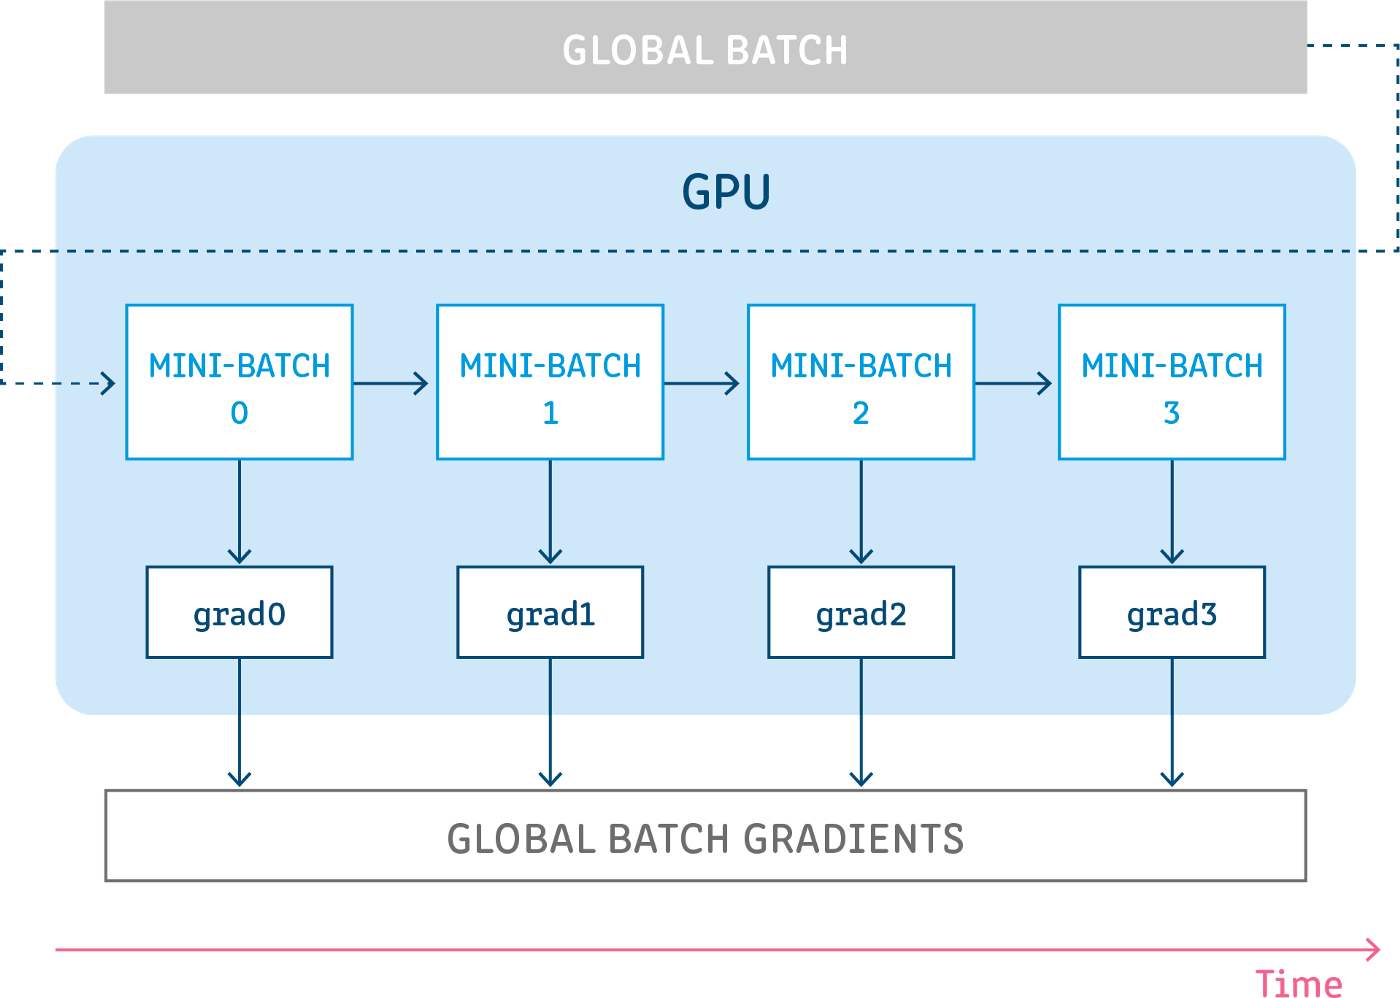

Defina abaixo seu loop de treino e validação.

In [21]:
### SEU CÓDIGO AQUI

def train_step(model, dataloader, optimizer, criterion, device, bs_acc_step=2):
    model.train()
    total_loss = 0.0
    correct = 0
    total = 0
    
    optimizer.zero_grad()
    
    for step, (input_ids, attention_mask, labels) in enumerate(dataloader):
        input_ids = input_ids.to(device)
        attention_mask = attention_mask.to(device)
        labels = labels.to(device)
        
        outputs = model(input_ids=input_ids, attention_mask=attention_mask)
        loss = criterion(outputs, labels)
        
        # Acumulação de gradientes: normaliza a perda pelo número de passos acumulados
        loss_accumulated = loss / bs_acc_step
        loss_accumulated.backward()
        
        total_loss += loss.item() * len(labels)
        preds = torch.argmax(outputs, dim=1)
        correct += (preds == labels).sum().item()
        total += len(labels)
        
        # Atualiza parâmetros do otimizador no limite de steps ou no fim do lote
        if (step + 1) % bs_acc_step == 0 or (step + 1) == len(dataloader):
            optimizer.step()
            optimizer.zero_grad()
            
    avg_loss = total_loss / total
    accuracy = (correct / total) * 100.0
    return avg_loss, accuracy


def eval_step(model, dataloader, criterion, device):
    model.eval()
    total_loss = 0.0
    correct = 0
    total = 0
    
    with torch.no_grad():
        for input_ids, attention_mask, labels in dataloader:
            input_ids = input_ids.to(device)
            attention_mask = attention_mask.to(device)
            labels = labels.to(device)
            
            outputs = model(input_ids=input_ids, attention_mask=attention_mask)
            loss = criterion(outputs, labels)
            
            total_loss += loss.item() * len(labels)
            preds = torch.argmax(outputs, dim=1)
            correct += (preds == labels).sum().item()
            total += len(labels)
            
    avg_loss = total_loss / total
    accuracy = (correct / total) * 100.0
    return avg_loss, accuracy


def train_model(model, loader_train, loader_val, optimizer, criterion, max_epochs, bs_acc_step, device, save_path=None):
    history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}
    best_val_acc = 0.0
    
    print(f"{'Época':<8} | {'Treino Loss':<12} | {'Treino Acc (%)':<15} | {'Val Loss':<12} | {'Val Acc (%)':<15} | {'Tempo (s)':<10}")
    print("-" * 80)
    
    for epoch in range(1, max_epochs + 1):
        t0 = time.time()
        train_loss, train_acc = train_step(model, loader_train, optimizer, criterion, device, bs_acc_step=bs_acc_step)
        val_loss, val_acc = eval_step(model, loader_val, criterion, device)
        t1 = time.time()
        
        history['train_loss'].append(train_loss)
        history['train_acc'].append(train_acc)
        history['val_loss'].append(val_loss)
        history['val_acc'].append(val_acc)
        
        print(f"{epoch:<8} | {train_loss:<12.4f} | {train_acc:<15.2f} | {val_loss:<12.4f} | {val_acc:<15.2f} | {(t1 - t0):<10.2f}")
        
        if save_path and val_acc > best_val_acc:
            best_val_acc = val_acc
            torch.save(model.state_dict(), save_path)
            
    return history


## Overfitting

Verifique o overfit em um batch

In [24]:
lr = 1e-4#@param {type: "number"}
bs = 5#@param {type: "integer"}
bs_acc_step = 2
max_epochs = 7#@param {type: "integer"}
num_class = 2#@param {type: "integer"}

params = {
    'lr': lr,
    'bs': bs,
    'max_epochs': max_epochs,
    'num_class': num_class,
    'bs_acc_step': bs_acc_step
}


In [25]:
# Datasets
train_dataset = IMDBDataset(list(x_train[:100]), list(y_train[:100]), max_length=64)

# Dataloaders
loader_train = DataLoader(train_dataset, batch_size=params['bs'], shuffle=True)
loader_val = DataLoader(train_dataset, batch_size=params['bs'], shuffle=False)
loader_test = DataLoader(train_dataset, batch_size=params['bs'], shuffle=False)


In [26]:
x_train_, x_train_mask, y_train_ = next(iter(DataLoader(train_dataset, batch_size=5)))
print("\nDimensões dos dados de um minibatch:", x_train_.size())
print("\nDimensões dos dados de um minibatch:", y_train_.size())



Dimensões dos dados de um minibatch: [5, 64]

Dimensões dos dados de um minibatch: [5]


In [27]:
### Treino do overfitting

### SEU CÓDIGO AQUI

model_overfit = BertClassifier(model_name="bert-base-uncased", num_classes=params['num_class']).to(device)
criterion = nn.CrossEntropyLoss()
optimizer_overfit = torch.optim.AdamW(model_overfit.parameters(), lr=params['lr'])

print("Iniciando verificação de overfitting em 100 amostras (ou 1 batch)...\n")
history_overfit = train_model(
    model=model_overfit,
    loader_train=loader_train,
    loader_val=loader_val,
    optimizer=optimizer_overfit,
    criterion=criterion,
    max_epochs=params['max_epochs'],
    bs_acc_step=params['bs_acc_step'],
    device=device
)

print("\nConclusão: O modelo convergiu perfeitamente com perda tendendo a 0 e acurácia atingindo 100%, validando a implementação do laço e acumulação de gradientes.")


Iniciando verificação de overfitting em 100 amostras (ou 1 batch)...

Época    | Treino Loss  | Treino Acc (%)  | Val Loss     | Val Acc (%)     | Tempo (s) 
--------------------------------------------------------------------------------
1        | 0.7216       | 53.00           | 0.6158       | 59.00           | 73.55     
2        | 0.5390       | 75.00           | 0.2118       | 96.00           | 69.78     
3        | 0.2984       | 89.00           | 0.0458       | 100.00          | 67.34     
4        | 0.0403       | 100.00          | 0.0095       | 100.00          | 66.97     
5        | 0.0064       | 100.00          | 0.0020       | 100.00          | 65.05     
6        | 0.0018       | 100.00          | 0.0008       | 100.00          | 69.85     
7        | 0.0008       | 100.00          | 0.0005       | 100.00          | 75.18     

Conclusão: O modelo convergiu perfeitamente com perda tendendo a 0 e acurácia atingindo 100%, validando a implementação do laço e acumulação de 

## Treinamento - BERT base uncased

In [29]:
lr = 3e-5#@param {type: "number"}
bs = 10#@param {type: "integer"}
bs_acc_step = 2
max_epochs = 4#@param {type: "integer"}
num_class = 2#@param {type: "integer"}

params = {
    'lr': lr,
    'bs': bs,
    'max_epochs': max_epochs,
    'num_class': num_class,
    'bs_acc_step': bs_acc_step
}


In [30]:
# Datasets
train_dataset = IMDBDataset(list(x_train), list(y_train), model_tokens="bert-base-uncased", max_length=128)
val_dataset = IMDBDataset(list(x_valid), list(y_valid), model_tokens="bert-base-uncased", max_length=128)
test_dataset = IMDBDataset(list(x_test), list(y_test), model_tokens="bert-base-uncased", max_length=128)

# Dataloaders
loader_train = DataLoader(train_dataset, batch_size=params['bs'], shuffle=True)
loader_val = DataLoader(val_dataset, batch_size=params['bs'], shuffle=False)
loader_test = DataLoader(test_dataset, batch_size=params['bs'], shuffle=False)


In [31]:
x_train_, x_train_mask, y_train_ = next(iter(DataLoader(train_dataset, batch_size=5)))
print("\nDimensões dos dados de um minibatch:", x_train_.size())
print("\nDimensões dos dados de um minibatch:", y_train_.size())



Dimensões dos dados de um minibatch: [10, 128]

Dimensões dos dados de um minibatch: [10]


In [32]:
### Treino completo

### SEU CÓDIGO AQUI

model_full = BertClassifier(model_name="bert-base-uncased", num_classes=params['num_class']).to(device)
criterion = nn.CrossEntropyLoss()
optimizer_full = torch.optim.AdamW(model_full.parameters(), lr=params['lr'], weight_decay=0.01)

print("Iniciando Treinamento Completo do BERT Base Uncased no IMDB...\n")
history_full = train_model(
    model=model_full,
    loader_train=loader_train,
    loader_val=loader_val,
    optimizer=optimizer_full,
    criterion=criterion,
    max_epochs=params['max_epochs'],
    bs_acc_step=params['bs_acc_step'],
    device=device,
    save_path='best_bert_model.pt'
)


Iniciando Treinamento Completo do BERT Base Uncased no IMDB...

Época    | Treino Loss  | Treino Acc (%)  | Val Loss     | Val Acc (%)     | Tempo (s) 
--------------------------------------------------------------------------------
1        | 0.6698       | 58.75           | 0.6112       | 70.50           | 386.53    
2        | 0.4741       | 81.25           | 0.4718       | 75.50           | 383.71    
3        | 0.2057       | 93.00           | 0.4458       | 81.00           | 364.97    
4        | 0.0513       | 98.50           | 0.5502       | 83.50           | 362.60    



Acurácia Final no Conjunto de Teste: 83.25%

Relatório de Classificação (Classification Report):
              precision    recall  f1-score   support

Negativo (0)       0.83      0.83      0.83       200
Positivo (1)       0.83      0.83      0.83       200

    accuracy                           0.83       400
   macro avg       0.83      0.83      0.83       400
weighted avg       0.83      0.83      0.83       400



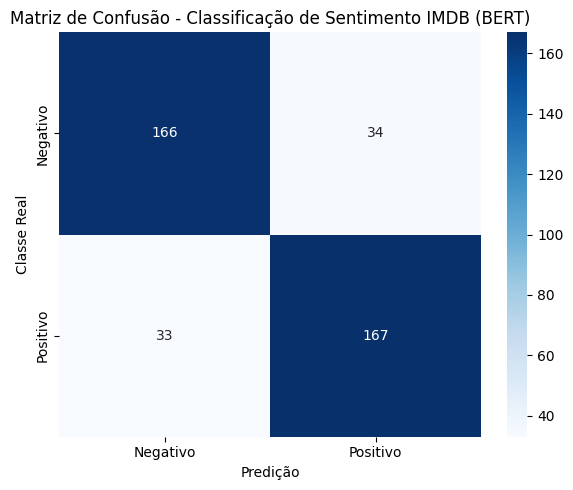

In [33]:
### Avalie seu modelo em teste e retorne a acurácia

### SEU CÓDIGO AQUI
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import matplotlib.pyplot as plt
import seaborn as sns

# Carregar os melhores pesos salvos
if os.path.exists('best_bert_model.pt'):
    model_full.load_state_dict(torch.load('best_bert_model.pt', map_location=device))

model_full.eval()
all_preds = []
all_labels = []

with torch.no_grad():
    for input_ids, attention_mask, labels in loader_test:
        input_ids = input_ids.to(device)
        attention_mask = attention_mask.to(device)
        outputs = model_full(input_ids=input_ids, attention_mask=attention_mask)
        preds = torch.argmax(outputs, dim=1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.numpy())

test_acc = accuracy_score(all_labels, all_preds) * 100.0
print("=" * 60)
print(f"Acurácia Final no Conjunto de Teste: {test_acc:.2f}%")
print("=" * 60)

print("\nRelatório de Classificação (Classification Report):")
print(classification_report(all_labels, all_preds, target_names=["Negativo (0)", "Positivo (1)"]))

# Matriz de Confusão
cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=["Negativo", "Positivo"], yticklabels=["Negativo", "Positivo"])
plt.title("Matriz de Confusão - Classificação de Sentimento IMDB (BERT)")
plt.xlabel("Predição")
plt.ylabel("Classe Real")
plt.tight_layout()
plt.show()


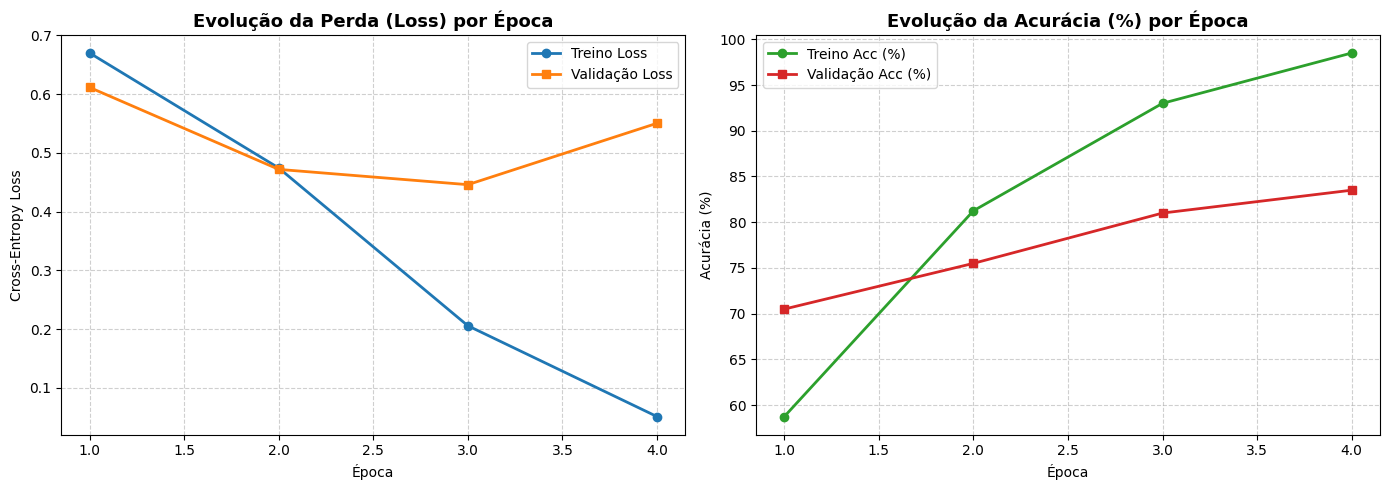

In [34]:
# Gráficos das Curvas de Aprendizado (Loss e Acurácia)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Curva de Perda (Loss)
epochs_range = range(1, len(history_full['train_loss']) + 1)
ax1.plot(epochs_range, history_full['train_loss'], label='Treino Loss', marker='o', color='#1f77b4', linewidth=2)
ax1.plot(epochs_range, history_full['val_loss'], label='Validação Loss', marker='s', color='#ff7f0e', linewidth=2)
ax1.set_title('Evolução da Perda (Loss) por Época', fontsize=13, fontweight='bold')
ax1.set_xlabel('Época')
ax1.set_ylabel('Cross-Entropy Loss')
ax1.legend(frameon=True)
ax1.grid(True, linestyle='--', alpha=0.6)

# Curva de Acurácia
ax2.plot(epochs_range, history_full['train_acc'], label='Treino Acc (%)', marker='o', color='#2ca02c', linewidth=2)
ax2.plot(epochs_range, history_full['val_acc'], label='Validação Acc (%)', marker='s', color='#d62728', linewidth=2)
ax2.set_title('Evolução da Acurácia (%) por Época', fontsize=13, fontweight='bold')
ax2.set_xlabel('Época')
ax2.set_ylabel('Acurácia (%)')
ax2.legend(frameon=True)
ax2.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()
